# Oysand: real Rayleigh dispersion to a depth-dependent shear field


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`period`，shape `(1, 30)`，dtype `<f8`：Wave periods in s, increasing order; equal to original wavelength divided by phase velocity.；`phase_velocity`，shape `(1, 30)`，dtype `<f8`：Observed fundamental Rayleigh phase velocity in km/s, matching period order.；`uncertainty`，shape `(1, 30)`，dtype `<f8`：Positive phase-velocity weight scale in km/s, half the published upper-minus-lower uncertainty interval.。未知量为四层Vs与前三层厚度组成的深度剪切速度场。

获取模型：层状弹性波边界/自由表面条件的Dunkin色散根产生Rayleigh相速度。

如何恢复：src.solvers.reconstruct/competitive_swarm：单调层速度条件下竞争粒子群全30点拟合。

GT与评价：没有独立GT；隐藏数组是指定方法输出，比较只说明方法一致性。

已有实验和图：cell6主动完整CPSO；7六图实测色散、深度剖面、上游、搜索/敏感性；8 Judge。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留1个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。层厚/速度边界是结构先验不是已知地质；测量区间半宽是权重尺度而非确认高斯sigma。

<!-- inverse-evidence-audit:20261026:end -->



## 1. Problem

Infer a four-layer shear-velocity-versus-depth profile from real fundamental-mode Rayleigh dispersion. Four velocities and three finite-layer thicknesses are seven independent unknowns; a finely drawn depth curve does not add observed degrees of freedom.

All supplied composite dispersion points are real Oysand surface-wave observations. The unknown is a four-layer spatial Vs(z) field with three finite-layer thicknesses and four shear velocities. Poisson ratios and density are known conditional priors. The last layer is a half-space. These are seven independent physical unknowns; plotting more depth samples does not add independent information.

At each angular frequency omega, horizontal wavenumber k=omega/c couples compressional and shear motion. Enforce zero traction at the free surface, continuous displacement/traction across every interface, and decay in the bottom half-space. The Dunkin compound-matrix formulation carries this boundary condition without the unstable cancellation of squared evanescent exponentials. Its secular function vanishes at the fundamental Rayleigh phase velocity. The inverse minimizes RMS((calculated-measured)/supplied uncertainty) across every observed period, under explicit layer bounds and monotone Vs.

The selected original CPSO method retains inertia, cognitive/social attraction, shrinking boundary repair, immediate best updates, competitive restarts and the exact40particle/300generation stopping path. The source restart radius divides by sqrt(4*11), whereas the paper divides by the bounds-span norm. The source also uses immediate best updates rather than the synchronous paper discussion; these are disclosed optimizer variants. An actual source-only controlled comparison measured247restarts/5643reset particles with the standard convention, versus14/174with only the paper radius changed. Their final weighted RMS values were0.11813111766049578and0.1100598188752683respectively. These are independently executed source comparisons, not fresh local alternative reconstructions. The local runtime explicitly executes both compound matrices/root finding and inverse updates with NumPy; no domain library, Numba or hidden optimizer result is used.


## 2. Data

All supplied Oysand periods, measured phase speeds and uncertainties are retained. The last layer is a half-space; density and Poisson ratios are fixed conditional priors. Internal km/km/s values convert to final m and m/s, preserving physical scale.

`data/raw_data.npz` contains the complete real composite dispersion curve, with batch axis first:

| Key | Shape | Dtype | Description |
|---|---|---|---|
| period | (1,30) | float64 | Wave periods in s, increasing order; equal to original wavelength divided by phase velocity. |
| phase_velocity | (1,30) | float64 | Observed fundamental Rayleigh phase velocity in km/s, matching period order. |
| uncertainty | (1,30) | float64 | Positive phase-velocity weight scale in km/s, half the published upper-minus-lower uncertainty interval. |

Acquisition metadata:

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Site | Oysand, Norway | - | Real near-surface surface-wave survey; released composite dispersion observations. |
| Mode | Fundamental Rayleigh phase | - | A single complete selected mode; not group speed or a higher mode. |
| Coordinate | z positive downward from surface | m | Horizontal layers; free surface at z=0. |
| Layers | 3finite plus1half-space | - | Four independently specified shear speeds, three finite interface increments. |
| Poisson ratio | 0.30,0.30,0.49,0.49 | dimensionless | Fixed by layer, surface downward. |
| Density | 1.95 in every layer | g/cm^3 | Fixed elastic prior, equal to1950kg/m^3. |
| Compressional speed | Vs*sqrt((1-nu)/(0.5-nu)) | same speed unit as Vs | Fixed isotropic-elastic relation. |
| Surface boundary | Zero normal/shear traction | - | Stress-free elastic surface. |
| Interface boundary | Continuous displacement/traction | - | Perfectly bonded interfaces. |
| Bottom boundary | Decaying elastic wave | - | Infinite half-space; no artificial reflecting bottom. |
| Uncertainty interpretation | Composite interval half-width | km/s | Supplied weighting scale, not a claim of independent Gaussian standard errors. |

The observations are supplied as processed dispersion measurements, not raw seismograms. Wave wavelengths are recoverable as period times phase speed after consistent unit conversion. No geological truth, target-fitted calibration or hidden spatial profile is provided. Density and Poisson ratios are modeling assumptions, so a recovered profile is conditional on them.


## 3. Physics

At angular frequency $\omega$, trial phase speed $c$ sets horizontal wavenumber $k=\omega/c$. Coupled compressional/shear solutions satisfy zero surface traction, interface continuity and bottom-half-space decay. The explicit Dunkin compound secular function vanishes at an allowed Rayleigh speed; measured dispersion constrains integrated depth behavior rather than pointwise local velocity.

Use all30 real Oysand composite fundamental-mode Rayleigh observations to infer a horizontally stratified four-layer shear-velocity field. Three finite layers lie over a half-space. Unknowns are their positive thicknesses h1,h2,h3 and the four positive shear velocities Vs1,...,Vs4. Density and Poisson ratio are fixed known assumptions. With depth z positive downward, Vs(z) is piecewise constant, with interfaces at h1,h1+h2,h1+h2+h3. The half-space extends indefinitely.

Use the conditional structural prior Vs1<=Vs2<=Vs3<=Vs4. Admissible thickness intervals are(0.4,1.2),(0.5,2.0),(4,12)m; corresponding velocity intervals are(80,160),(100,180),(120,220),(150,280)m/s. These define the allowed layered parameterization, not measurements of the true geology.

For period T, let angular frequency omega=2*pi/T and horizontal wavenumber k=omega/c, where c is the predicted phase velocity. Compressional speed is Vp=Vs*sqrt((1-nu)/(0.5-nu)), where nu is Poisson ratio. The elastic displacement u obeys


$$
-\rho\omega^2\mathbf u=(\lambda+\mu)\nabla(\nabla\cdot\mathbf u)+\mu\nabla^2\mathbf u,
\qquad \mu=\rho V_s^2,\quad \lambda=\rho(V_p^2-2V_s^2).
$$


Here rho is density and lambda,mu are the Lame moduli. The surface has zero normal and shear traction. Displacement and traction are continuous at interfaces; the bottom half-space admits decaying waves. These conditions define a secular function D(c,T;h,Vs), whose fundamental-mode zero gives c. The observations satisfy measured c(T)=predicted c(T)+error, with supplied uncertainty widths defining residual weights. Recovering interface depths and velocities jointly is nonlinear and nonunique over a finite period band.


## 4. Method

The local CPSO search retains 40 particles, 300 generations, monotone-Vs rejection, shrinking boundary repair, immediate best updates and competitive restarts. The source-specific restart radius and controlled paper-radius comparison remain disclosed variants, not silently corrected optimizer equations.

Use a stable layered elastic-wave secular function and bracket the fundamental phase-velocity root for each period. A compound-matrix representation avoids unstable exponential cancellation in thick or high-frequency layers. Joint thickness/velocity search is multimodal; a bounded particle-swarm family with monotonic-velocity prior and competitive restarts is suitable. Minimize uncertainty-weighted dispersion RMS while keeping all periods and all seven physical unknowns explicit. Numerical restart radius conventions depend on optimization coordinates and must be declared.


## 5. Results

The active full inverse retains all parameter checks, measured/original/fresh dispersion curves, full search/population histories, explored low-misfit models and seven actual plus/minus-one-percent forward sensitivities. The explored ensemble is an optimization sample, not a posterior.

### Real outputs, all unknowns and actual search history

The original reference is an independently executed evodcinv/stochopy/disba inversion on the same complete observations. It is a standard-method result, not geological truth. We show original and fresh dispersion curves, the reconstructed piecewise depth field, every finite layer thickness, actual population and best-loss histories, and low-misfit explored models. The explored ensemble is an optimization sample, not a Bayesian posterior. Thickness/velocity tradeoffs and limited penetration make uniqueness conditional on the chosen elastic priors and parameterization.

The final sensitivity panel actually perturbs each of the seven unknowns by plus/minus1percent and recomputes the local physical forward solution. The exact reported finite-difference response is (c(p*1.01)-c(p*.99))/(.02*c_observed), where p is each positive thickness or velocity and c_observed is the measured speed at that period. This is an observation-speed-normalized response, not an exact logarithmic model derivative. It illustrates which periods constrain which depths; it does not substitute an unexecuted alternative inversion.

The actual reconstruction passes all seven geometric/elastic unknown checks and the complete dispersion check. The curves, full search history and sensitivity reveal the measurement fit and nonuniqueness directly. No cached original reconstruction is labeled as fresh, and no additional depth samples are counted as unknowns.


In [1]:
from pathlib import Path
import os,sys,time,json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
print('Executed interpreter:',sys.executable,sys.version)
print('NumPy:',np.__version__)
if os.name=='nt':
    import ctypes
    from ctypes import wintypes
    kernel_api=ctypes.WinDLL('kernel32',use_last_error=True)
    kernel_api.GetCurrentProcess.restype=wintypes.HANDLE
    kernel_api.GetProcessAffinityMask.argtypes=[wintypes.HANDLE,ctypes.POINTER(ctypes.c_size_t),ctypes.POINTER(ctypes.c_size_t)]
    process_mask=ctypes.c_size_t();system_mask=ctypes.c_size_t()
    assert kernel_api.GetProcessAffinityMask(kernel_api.GetCurrentProcess(),ctypes.byref(process_mask),ctypes.byref(system_mask))
    print('Executed kernel affinity mask:',process_mask.value,'system mask:',system_mask.value)

root=Path.cwd()
if not (root/'src').exists():root=root.parent
os.chdir(root);sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.visualization import make_figures
started=time.perf_counter();data=load_data()
def progress(iteration,loss):
    if iteration%50==0:print('Generation',iteration,'weighted RMS',loss,'elapsed seconds',time.perf_counter()-started,flush=True)
output,stages=reconstruct(data,callback=progress)
seconds=time.perf_counter()-started
(root/'output').mkdir(exist_ok=True);np.savez_compressed(root/'output/reconstruction.npz',**output)
print('Complete fresh raw-data inversion seconds:',seconds)
print('Layer Vs [m/s]:',output['reconstruction'][0]);print('Finite thicknesses [m]:',output['thickness'][0])


Executed interpreter: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe 3.11.11 (main, Mar 17 2025, 21:01:29) [MSC v.1943 64 bit (AMD64)]
NumPy: 2.4.6
Executed kernel affinity mask: 4 system mask: 4294967295


Generation 50 weighted RMS 0.37420902474694373 elapsed seconds 101.11387710000417


Generation 100 weighted RMS 0.370802983158351 elapsed seconds 207.85548279999784


Generation 150 weighted RMS 0.2900924443089721 elapsed seconds 319.9291271999973


Generation 200 weighted RMS 0.18688762307555604 elapsed seconds 442.98363360000076


Generation 250 weighted RMS 0.15120247481225543 elapsed seconds 580.9590152000019


Generation 300 weighted RMS 0.11813111766049578 elapsed seconds 725.6021327999988


Complete fresh raw-data inversion seconds: 725.6045534000004
Layer Vs [m/s]: [104.61739162 135.67993612 182.09733264 194.88741521]
Finite thicknesses [m]: [0.6817349  1.32877973 9.43042163]


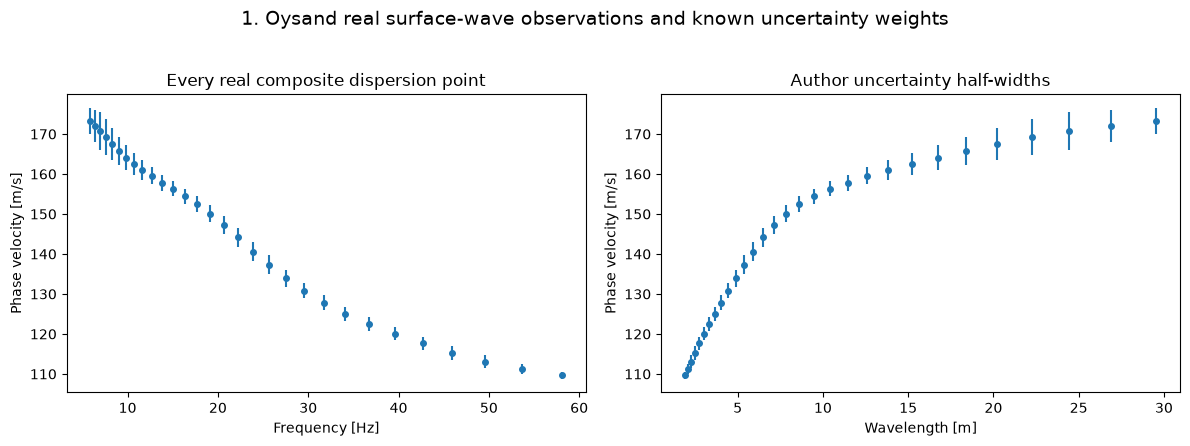

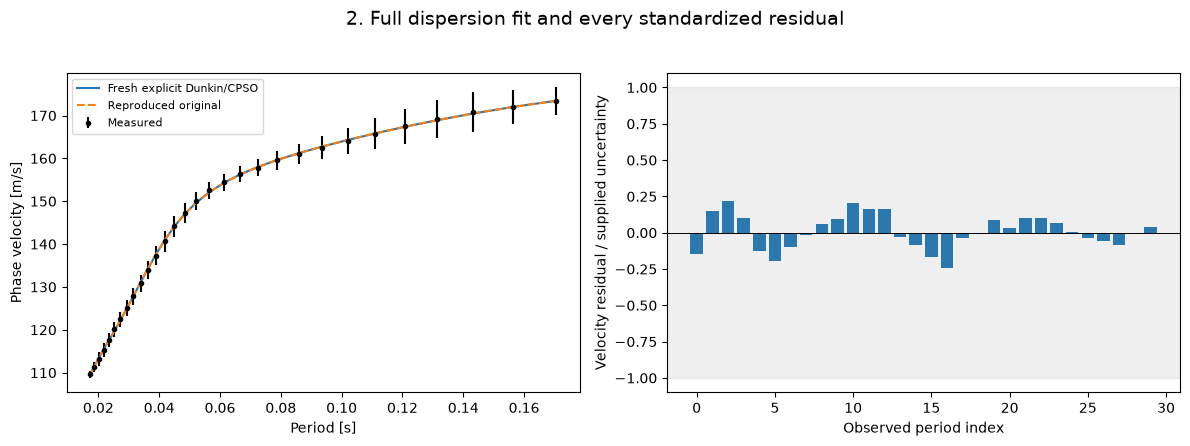

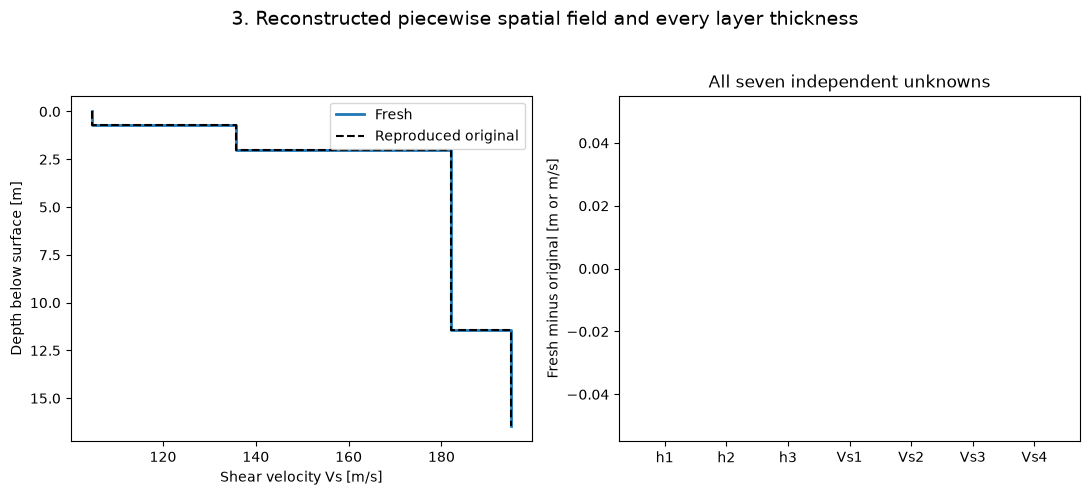

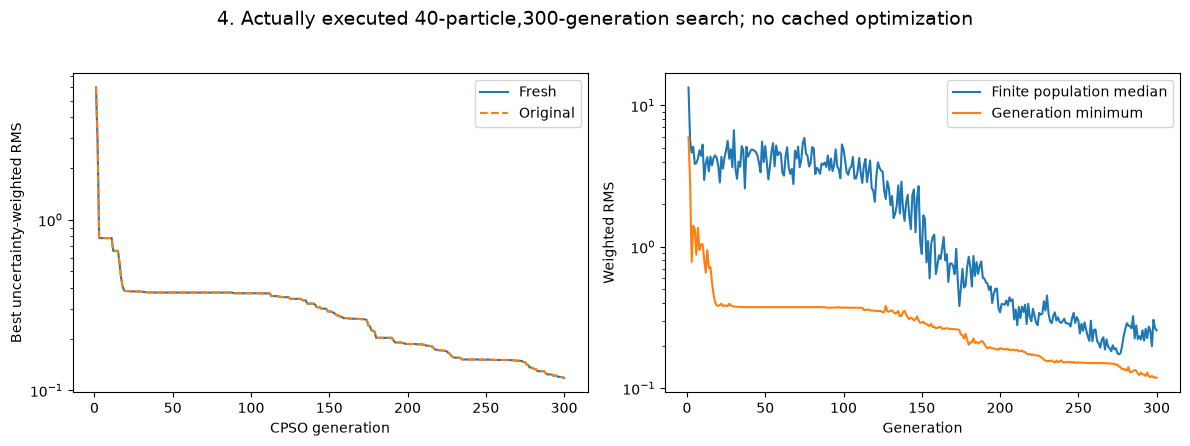

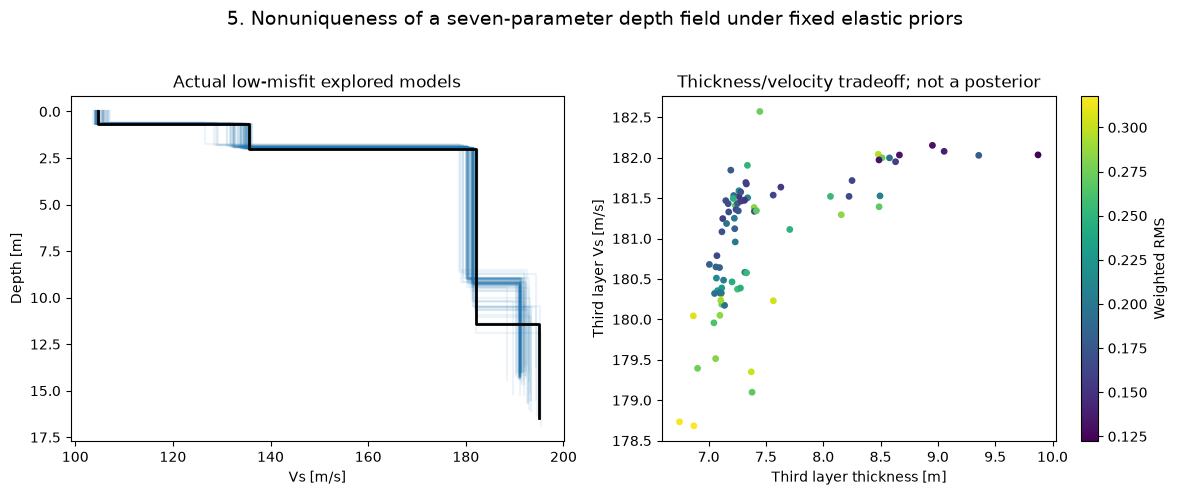

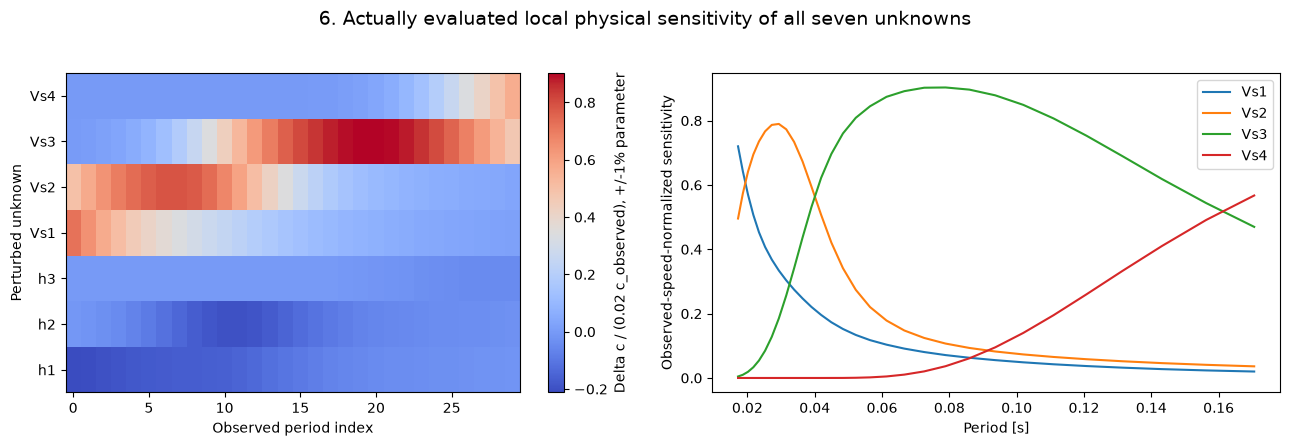

In [2]:
with np.load(root/'notebooks/reference_outputs/upstream_original.npz',allow_pickle=False) as z:source={k:z[k] for k in z.files}
export=Path('D:/yan1/agent/AutoSkill/imaging-101-maintainer/research_batch5_20261021/astro_earth/figures/oysand_rayleigh_shear_profile')
figures=make_figures(data,output,stages,source,export)
for fig in figures:
    display(fig)
    plt.close(fig)


In [3]:
import subprocess
result=subprocess.run([sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json'],capture_output=True,text=True)
report=json.loads((root/'output/judge_report.json').read_text(encoding='utf8'))
print(json.dumps(report,indent=2));assert result.returncode==0,result.stderr
(export/'metrics.json').write_text(json.dumps({'fresh':report,'complete_reconstruction_seconds':seconds,'final_weighted_objective':float(stages['best_objective'])},indent=2),encoding='utf8')


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "velocity_1_absolute_error": 0.0,
    "velocity_2_absolute_error": 0.0,
    "velocity_3_absolute_error": 0.0,
    "velocity_4_absolute_error": 0.0,
    "thickness_1_absolute_error": 0.0,
    "thickness_2_absolute_error": 0.0,
    "thickness_3_absolute_error": 0.0,
    "weighted_dispersion_rms": 0.11813111766049578
  },
  "thresholds": {
    "velocity_1_absolute_error": {
      "comparison": "<=",
      "boundary": 4.703581208343819
    },
    "velocity_2_absolute_error": {
      "comparison": "<=",
      "boundary": 3.414198331353353
    },
    "velocity_3_absolute_error": {
      "comparison": "<=",
      "boundary": 1.020170840213126
    },
    "velocity_4_absolute_error": {
      "comparison": "<=",
      "boundary": 6.182011976619635
    },
    "thickness_1_absolute_error": {
      "comparison": "<=",
      "boundary": 0.16412663952910225
    },
    "thickness_2_absolute_error": {
      "comparison": "<=",
      "boundary":

1473

## 6. Conclusion

The retained complete-parameter and weighted-dispersion checks support reproduction of this conditional layered model. Thickness/velocity tradeoffs, finite penetration and fixed elastic priors prevent a uniquely known geological profile.

### Independent evaluation and interpretation

Every layer velocity and every finite thickness is evaluated, together with a full uncertainty-weighted dispersion observation criterion. Bounds are fixed from additional independent original searches rather than a hidden physical truth or the fresh output's self-comparison. The standalone evaluator loads only submitted fields and public period/calibration information and imports no reconstruction code. Its finite values and threshold comparisons are shown below. Agreement with this conditional elastic model does not identify geology uniquely or establish a true subsurface profile.
